# CNT-Based Fly Ash–Slag Backfill Failure-Stage Prediction  
## Notebook 01 — Build the synchronized master dataset

This notebook uses the **verified file structures**:

### UCS Excel files
Sheet: `Sheet1`

Required columns:
- `Time_s`
- `Stress_MPa`
- `Strain`

### Infrared CSV files
Required columns:
- `Time_s`
- `AIRT_C`
- `VSMIT`

The final modelling variables are restricted to:

\[
\{\mathrm{Stress\_MPa},\ \mathrm{Strain},\ \mathrm{AIRT\_C},\ \mathrm{VSMIT}\}
\]

The notebook matches files by specimen ID, synchronizes the UCS and infrared signals, performs quality-control checks, generates necessary figures in Times New Roman, and exports the master dataset.


## Expected project structure

```text
Project_Dir/
├── exp_samp.xlsx
├── UCS/
│   ├── G1-1_processed.xlsx
│   ├── G1-2_processed.xlsx
│   └── ...
└── IR/
    ├── G1-1_AIRT_VSMIT.csv
    ├── G1-2_AIRT_VSMIT.csv
    └── ...
```

Only change `PROJECT_DIR` in the configuration cell.


In [1]:
# ============================================================
# 1. Imports and publication plotting style
# ============================================================

from pathlib import Path
import re
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

warnings.filterwarnings("ignore")

# Times New Roman for journal figures
available_fonts = {f.name for f in font_manager.fontManager.ttflist}
FONT_NAME = "Times New Roman" if "Times New Roman" in available_fonts else "DejaVu Serif"

if FONT_NAME != "Times New Roman":
    print(
        "WARNING: Times New Roman is not installed or not visible to Python. "
        "DejaVu Serif will be used temporarily."
    )

plt.rcParams.update({
    "font.family": FONT_NAME,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "axes.linewidth": 1.0,
    "lines.linewidth": 1.3,
    "figure.dpi": 120,
    "savefig.dpi": 600,
    "figure.autolayout": True
})

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

print("Plot font:", FONT_NAME)


Plot font: Times New Roman


In [2]:
# ============================================================
# 2. Project configuration
# ============================================================

# CHANGE THIS PATH
PROJECT_DIR = Path(r"C:\Users\Eddie\Desktop\new_exp_june\Project_Dir")

UCS_DIR = PROJECT_DIR / "UCS"
IR_DIR = PROJECT_DIR / "IR"
METADATA_FILE = PROJECT_DIR / "exp_samp.xlsx"

OUTPUT_DIR = PROJECT_DIR / "master_dataset_outputs"
FIGURE_DIR = OUTPUT_DIR / "figures"
QC_DIR = OUTPUT_DIR / "qc_tables"

for directory in [OUTPUT_DIR, FIGURE_DIR, QC_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

# Synchronization configuration
RESET_EACH_SIGNAL_TO_ZERO = True

# Default: interpolate infrared data onto the UCS time points.
# This preserves the mechanical-test sampling structure.
TARGET_TIME_STEP_S = None

# Set manual offsets only if later inspection shows that one recording
# started earlier than the other.
UCS_TIME_OFFSET_S = 0.0
IR_TIME_OFFSET_S = 0.0

# Retain only the overlapping time interval.
TRIM_TO_COMMON_TIME = True

# The first IR row normally has no VSMIT because there is no preceding frame.
# Interpolation will begin from the first available non-missing VSMIT value.
MIN_SYNCHRONIZED_ROWS = 10

print("Project directory:", PROJECT_DIR)
print("UCS directory:", UCS_DIR)
print("IR directory:", IR_DIR)


Project directory: C:\Users\Eddie\Desktop\new_exp_june\Project_Dir
UCS directory: C:\Users\Eddie\Desktop\new_exp_june\Project_Dir\UCS
IR directory: C:\Users\Eddie\Desktop\new_exp_june\Project_Dir\IR


In [3]:
# ============================================================
# 3. Verified columns and helper functions
# ============================================================

UCS_REQUIRED_COLUMNS = ["Time_s", "Stress_MPa", "Strain"]
IR_REQUIRED_COLUMNS = ["Time_s", "AIRT_C", "VSMIT"]

def normalize_sample_id(filename):
    """Extract a common specimen ID from UCS and IR file names."""
    stem = Path(filename).stem.strip()

    stem = re.sub(r"_processed$", "", stem, flags=re.IGNORECASE)
    stem = re.sub(r"_AIRT_VSMIT$", "", stem, flags=re.IGNORECASE)

    stem = stem.replace("_", "-")
    stem = re.sub(r"\s+", "", stem)
    stem = re.sub(r"-+", "-", stem)

    return stem.upper().strip("-")

def list_files(folder, suffixes):
    return sorted(
        file for file in folder.iterdir()
        if file.is_file() and file.suffix.lower() in suffixes
    )

def validate_columns(df, required, filename):
    missing = [column for column in required if column not in df.columns]
    if missing:
        raise KeyError(
            f"{filename} is missing required columns: {missing}. "
            f"Available columns: {list(df.columns)}"
        )

def numeric_frame(df, columns):
    output = df[columns].copy()

    for column in columns:
        output[column] = pd.to_numeric(output[column], errors="coerce")

    output = output.replace([np.inf, -np.inf], np.nan)
    return output

def clean_time_series(df, signal_columns, reset_to_zero=True, time_offset=0.0):
    output = df.copy()
    output = output.dropna(subset=["Time_s"])
    output = output.sort_values("Time_s")

    # Average duplicate time points if they exist.
    output = output.groupby("Time_s", as_index=False).mean(numeric_only=True)

    if reset_to_zero:
        output["Time_s"] = output["Time_s"] - output["Time_s"].min()

    output["Time_s"] = output["Time_s"] + time_offset

    # Remove rows where all signals are missing.
    output = output.dropna(subset=signal_columns, how="all")
    output = output.reset_index(drop=True)

    return output

def interpolate_signal(source_time, source_values, target_time):
    """
    Linear interpolation without extrapolation.
    Missing source values, including the first blank VSMIT observation,
    are ignored.
    """
    source_time = np.asarray(source_time, dtype=float)
    source_values = np.asarray(source_values, dtype=float)
    target_time = np.asarray(target_time, dtype=float)

    valid = np.isfinite(source_time) & np.isfinite(source_values)

    if valid.sum() < 2:
        return np.full(target_time.shape, np.nan, dtype=float)

    x = source_time[valid]
    y = source_values[valid]

    order = np.argsort(x)
    x = x[order]
    y = y[order]

    x, unique_indices = np.unique(x, return_index=True)
    y = y[unique_indices]

    interpolated = np.interp(target_time, x, y)

    # Prevent extrapolation beyond the available source interval.
    interpolated[target_time < x.min()] = np.nan
    interpolated[target_time > x.max()] = np.nan

    return interpolated

def synchronize_ucs_ir(ucs, ir, fixed_step_s=None):
    common_start = max(ucs["Time_s"].min(), ir["Time_s"].min())
    common_end = min(ucs["Time_s"].max(), ir["Time_s"].max())

    if common_end <= common_start:
        raise ValueError("UCS and IR files have no overlapping time range.")

    if fixed_step_s is None:
        target_time = ucs["Time_s"].to_numpy(dtype=float)

        if TRIM_TO_COMMON_TIME:
            target_time = target_time[
                (target_time >= common_start) &
                (target_time <= common_end)
            ]

        synchronization_method = "IR interpolated onto UCS time grid"
    else:
        target_time = np.arange(
            common_start,
            common_end + fixed_step_s / 2,
            fixed_step_s
        )
        synchronization_method = f"Common fixed grid ({fixed_step_s:g} s)"

    merged = pd.DataFrame({"Time_s": target_time})

    merged["Stress_MPa"] = interpolate_signal(
        ucs["Time_s"], ucs["Stress_MPa"], target_time
    )
    merged["Strain"] = interpolate_signal(
        ucs["Time_s"], ucs["Strain"], target_time
    )
    merged["AIRT_C"] = interpolate_signal(
        ir["Time_s"], ir["AIRT_C"], target_time
    )
    merged["VSMIT"] = interpolate_signal(
        ir["Time_s"], ir["VSMIT"], target_time
    )

    # A complete record is required for subsequent modelling.
    merged = merged.dropna(
        subset=["Stress_MPa", "Strain", "AIRT_C", "VSMIT"],
        how="any"
    ).reset_index(drop=True)

    if len(merged) < MIN_SYNCHRONIZED_ROWS:
        raise ValueError(
            f"Only {len(merged)} synchronized complete rows remain."
        )

    return merged, synchronization_method


In [4]:
# ============================================================
# 4. Discover and match UCS and IR files
# ============================================================

if not UCS_DIR.exists():
    raise FileNotFoundError(f"UCS folder does not exist: {UCS_DIR}")

if not IR_DIR.exists():
    raise FileNotFoundError(f"IR folder does not exist: {IR_DIR}")

ucs_files = list_files(UCS_DIR, {".xlsx", ".xls"})
ir_files = list_files(IR_DIR, {".csv"})

ucs_map = {}
for file in ucs_files:
    sample_id = normalize_sample_id(file.name)
    if sample_id in ucs_map:
        raise ValueError(f"Duplicate UCS specimen ID: {sample_id}")
    ucs_map[sample_id] = file

ir_map = {}
for file in ir_files:
    sample_id = normalize_sample_id(file.name)
    if sample_id in ir_map:
        raise ValueError(f"Duplicate IR specimen ID: {sample_id}")
    ir_map[sample_id] = file

all_sample_ids = sorted(set(ucs_map) | set(ir_map))

matching_report = pd.DataFrame({
    "Sample_ID": all_sample_ids,
    "UCS_File": [
        ucs_map[sample_id].name if sample_id in ucs_map else None
        for sample_id in all_sample_ids
    ],
    "IR_File": [
        ir_map[sample_id].name if sample_id in ir_map else None
        for sample_id in all_sample_ids
    ]
})

matching_report["Matched"] = (
    matching_report["UCS_File"].notna() &
    matching_report["IR_File"].notna()
)

matched_sample_ids = matching_report.loc[
    matching_report["Matched"], "Sample_ID"
].tolist()

display(matching_report.head(20))

print("UCS files detected:", len(ucs_files))
print("IR files detected:", len(ir_files))
print("Matched specimen pairs:", len(matched_sample_ids))
print("UCS files without matching IR:", (
    matching_report["UCS_File"].notna() &
    matching_report["IR_File"].isna()
).sum())
print("IR files without matching UCS:", (
    matching_report["UCS_File"].isna() &
    matching_report["IR_File"].notna()
).sum())

matching_report.to_csv(
    QC_DIR / "01_file_matching_report.csv",
    index=False
)


,Sample_ID,UCS_File,IR_File,Matched
0,G1-1,G1-1_processed.xlsx,G1-1_AIRT_VSMIT.csv,True
1,G1-10,G1-10_processed.xlsx,G1-10_AIRT_VSMIT.csv,True
2,G1-11,G1-11_processed.xlsx,G1-11_AIRT_VSMIT.csv,True
3,G1-12,G1-12_processed.xlsx,G1-12_AIRT_VSMIT.csv,True
4,G1-13,G1-13_processed.xlsx,G1-13_AIRT_VSMIT.csv,True
5,G1-14,G1-14_processed.xlsx,G1-14_AIRT_VSMIT.csv,True
6,G1-15,G1-15_processed.xlsx,G1-15_AIRT_VSMIT.csv,True
7,G1-16,G1-16_processed.xlsx,G1-16_AIRT_VSMIT.csv,True
8,G1-17,G1-17_processed.xlsx,G1-17_AIRT_VSMIT.csv,True
9,G1-18,G1-18_processed.xlsx,G1-18_AIRT_VSMIT.csv,True


UCS files detected: 81
IR files detected: 80
Matched specimen pairs: 80
UCS files without matching IR: 1
IR files without matching UCS: 0


In [5]:
# ============================================================
# 5. Inspect the verified structure using one matched specimen
# ============================================================

if not matched_sample_ids:
    raise RuntimeError("No matching UCS and IR file pairs were found.")

example_id = matched_sample_ids[0]

example_ucs = pd.read_excel(
    ucs_map[example_id],
    sheet_name="Sheet1"
)
example_ir = pd.read_csv(
    ir_map[example_id]
)

validate_columns(
    example_ucs,
    UCS_REQUIRED_COLUMNS,
    ucs_map[example_id].name
)
validate_columns(
    example_ir,
    IR_REQUIRED_COLUMNS,
    ir_map[example_id].name
)

print("Example specimen:", example_id)
print("\nUCS columns:")
print(example_ucs.columns.tolist())
display(example_ucs[UCS_REQUIRED_COLUMNS].head())

print("\nIR columns:")
print(example_ir.columns.tolist())
display(example_ir[IR_REQUIRED_COLUMNS].head(10))

print(
    "\nFirst VSMIT value:",
    example_ir.loc[0, "VSMIT"]
)


Example specimen: G1-1

UCS columns:
['Force_N', 'Axial_Deformation_mm', 'Lateral_Deformation_mm', 'Displacement_mm', 'Crosshead_Speed_mm_min', 'Time_ms', 'True_Stress', 'True_Strain', 'Time_s', 'Stress_MPa', 'Strain', 'Strain_percent']


,Time_s,Stress_MPa,Strain
0,0.125,0.008862,0.000003
1,0.234,0.008862,0.000003
2,0.343,0.009167,0.000012
3,0.468,0.009778,0.000021
4,0.577,0.010084,0.000030



IR columns:
['Time_s', 'AIRT_C', 'VSMIT']


,Time_s,AIRT_C,VSMIT
0,0.000000,33.036254,NaN
1,0.033333,33.036730,0.002341
2,0.066667,33.034544,0.002275
3,0.100000,33.029846,0.002146
4,0.133333,33.036642,0.002229
5,0.166667,33.040460,0.002297
6,0.200000,33.035663,0.002170
7,0.233333,33.036439,0.002153
8,0.266667,33.042388,0.002057
9,0.300000,33.038643,0.002105



First VSMIT value: nan


In [6]:
# ============================================================
# 6. Optional specimen metadata
# ============================================================

metadata = None
metadata_sample_id_column = None

if METADATA_FILE.exists():
    metadata = pd.read_excel(METADATA_FILE)
    metadata.columns = [str(column).strip() for column in metadata.columns]

    possible_id_columns = [
        "Sample_ID",
        "Sample ID",
        "Sample",
        "Specimen_ID",
        "Specimen ID",
        "Specimen"
    ]

    for candidate in possible_id_columns:
        if candidate in metadata.columns:
            metadata_sample_id_column = candidate
            break

    if metadata_sample_id_column is not None:
        metadata["Sample_ID"] = (
            metadata[metadata_sample_id_column]
            .astype(str)
            .map(normalize_sample_id)
        )
        metadata = metadata.drop_duplicates("Sample_ID")

        print("Metadata ID column:", metadata_sample_id_column)
        print("Metadata specimens:", len(metadata))
        display(metadata.head())
    else:
        print(
            "Metadata file was found, but no recognized specimen-ID "
            "column was detected. Metadata will not be merged."
        )
        print("Metadata columns:", metadata.columns.tolist())
else:
    print("Metadata file was not found. Signal synchronization can continue.")


Metadata file was found, but no recognized specimen-ID column was detected. Metadata will not be merged.
Metadata columns: ['SN', 'New_Sample_ID', 'FA (50%)', 'Slag(50%)', 'SS(%)', 'SS (g)', 'CNT (%)', 'CNT (g)', 'Water (g)', 'Liquid (g)', 'Curing_Day', 'S:W Ratio', 'Solid', 'Liquid', 'Diameter', 'Mass', 'Height', 'Density']


In [7]:
# ============================================================
# 7. Build the synchronized master dataset
# ============================================================

master_parts = []
qc_records = []
error_records = []

for number, sample_id in enumerate(matched_sample_ids, start=1):
    ucs_path = ucs_map[sample_id]
    ir_path = ir_map[sample_id]

    try:
        # Read verified file types and sheet.
        ucs_raw = pd.read_excel(
            ucs_path,
            sheet_name="Sheet1"
        )
        ir_raw = pd.read_csv(ir_path)

        validate_columns(
            ucs_raw,
            UCS_REQUIRED_COLUMNS,
            ucs_path.name
        )
        validate_columns(
            ir_raw,
            IR_REQUIRED_COLUMNS,
            ir_path.name
        )

        # Retain only the required columns.
        ucs = numeric_frame(
            ucs_raw,
            UCS_REQUIRED_COLUMNS
        )
        ir = numeric_frame(
            ir_raw,
            IR_REQUIRED_COLUMNS
        )

        # Clean the two signals independently.
        ucs = clean_time_series(
            ucs,
            signal_columns=["Stress_MPa", "Strain"],
            reset_to_zero=RESET_EACH_SIGNAL_TO_ZERO,
            time_offset=UCS_TIME_OFFSET_S
        )

        ir = clean_time_series(
            ir,
            signal_columns=["AIRT_C", "VSMIT"],
            reset_to_zero=RESET_EACH_SIGNAL_TO_ZERO,
            time_offset=IR_TIME_OFFSET_S
        )

        # Synchronize.
        synchronized, method = synchronize_ucs_ir(
            ucs,
            ir,
            fixed_step_s=TARGET_TIME_STEP_S
        )

        synchronized.insert(0, "Sample_ID", sample_id)
        synchronized.insert(
            1,
            "Observation_ID",
            np.arange(1, len(synchronized) + 1)
        )

        duration = (
            synchronized["Time_s"].max() -
            synchronized["Time_s"].min()
        )

        synchronized["Test_Progress"] = (
            (
                synchronized["Time_s"] -
                synchronized["Time_s"].min()
            ) / duration
            if duration > 0
            else 0.0
        )

        synchronized["UCS_File"] = ucs_path.name
        synchronized["IR_File"] = ir_path.name
        synchronized["Synchronization_Method"] = method

        master_parts.append(synchronized)

        qc_records.append({
            "Sample_ID": sample_id,
            "UCS_Raw_Rows": len(ucs_raw),
            "IR_Raw_Rows": len(ir_raw),
            "UCS_Clean_Rows": len(ucs),
            "IR_Clean_Rows": len(ir),
            "Synchronized_Rows": len(synchronized),
            "Synchronized_Start_s": synchronized["Time_s"].min(),
            "Synchronized_End_s": synchronized["Time_s"].max(),
            "Synchronized_Duration_s": duration,
            "Peak_Stress_MPa_QC": synchronized["Stress_MPa"].max(),
            "Maximum_Strain_QC": synchronized["Strain"].max(),
            "Minimum_AIRT_C_QC": synchronized["AIRT_C"].min(),
            "Maximum_AIRT_C_QC": synchronized["AIRT_C"].max(),
            "Mean_VSMIT_QC": synchronized["VSMIT"].mean(),
            "Status": "Success"
        })

        print(
            f"[{number:02d}/{len(matched_sample_ids):02d}] "
            f"{sample_id}: {len(synchronized):,} synchronized rows"
        )

    except Exception as error:
        error_records.append({
            "Sample_ID": sample_id,
            "UCS_File": ucs_path.name,
            "IR_File": ir_path.name,
            "Error": str(error)
        })

        print(
            f"[{number:02d}/{len(matched_sample_ids):02d}] "
            f"{sample_id}: ERROR — {error}"
        )

if not master_parts:
    raise RuntimeError(
        "No sample was processed successfully. "
        "Inspect the printed errors."
    )

master = pd.concat(master_parts, ignore_index=True)
qc_summary = pd.DataFrame(qc_records)
processing_errors = pd.DataFrame(error_records)

print("\nSuccessfully processed specimens:", master["Sample_ID"].nunique())
print("Master rows:", f"{len(master):,}")
print("Processing errors:", len(processing_errors))

display(qc_summary.head())

if not processing_errors.empty:
    display(processing_errors)


[01/80] G1-1: 4,352 synchronized rows
[02/80] G1-10: 3,757 synchronized rows
[03/80] G1-11: 2,277 synchronized rows
[04/80] G1-12: 4,277 synchronized rows
[05/80] G1-13: 2,474 synchronized rows
[06/80] G1-14: 3,522 synchronized rows
[07/80] G1-15: 2,093 synchronized rows
[08/80] G1-16: 3,077 synchronized rows
[09/80] G1-17: 4,202 synchronized rows
[10/80] G1-18: 2,653 synchronized rows
[11/80] G1-19: 4,235 synchronized rows
[12/80] G1-2: 3,267 synchronized rows
[13/80] G1-20: 2,147 synchronized rows
[14/80] G1-3: 1,857 synchronized rows
[15/80] G1-4: 3,719 synchronized rows
[16/80] G1-5: 3,759 synchronized rows
[17/80] G1-6: 2,696 synchronized rows
[18/80] G1-7: 3,355 synchronized rows
[19/80] G1-8: 2,276 synchronized rows
[20/80] G1-9: 2,352 synchronized rows
[21/80] G2-1: 3,179 synchronized rows
[22/80] G2-10: 3,377 synchronized rows
[23/80] G2-11: 2,735 synchronized rows
[24/80] G2-12: 3,245 synchronized rows
[25/80] G2-13: 2,478 synchronized rows
[26/80] G2-14: 3,397 synchronized r

,Sample_ID,UCS_Raw_Rows,IR_Raw_Rows,UCS_Clean_Rows,IR_Clean_Rows,Synchronized_Rows,Synchronized_Start_s,Synchronized_End_s,Synchronized_Duration_s,Peak_Stress_MPa_QC,Maximum_Strain_QC,Minimum_AIRT_C_QC,Maximum_AIRT_C_QC,Mean_VSMIT_QC,Status
0,G1-1,4353,15406,4353,15406,4352,0.109,484.832,484.723,10.289711,0.037825,32.656294,33.039031,0.002221,Success
1,G1-10,3758,13362,3758,13362,3757,0.125,418.564,418.439,18.225864,0.033757,31.997580,32.242350,0.001887,Success
2,G1-11,2278,7714,2278,7714,2277,0.125,253.703,253.578,30.371652,0.019713,32.355302,32.518674,0.001922,Success
3,G1-12,4278,14370,4278,14370,4277,0.109,476.470,476.361,31.234909,0.038718,31.628429,31.917847,0.001779,Success
4,G1-13,2475,8359,2475,8359,2474,0.109,275.621,275.512,20.972089,0.021213,31.634719,31.875159,0.001776,Success


In [8]:
# ============================================================
# 8. Merge specimen metadata
# ============================================================

if (
    metadata is not None and
    metadata_sample_id_column is not None
):
    metadata_for_merge = metadata.drop(
        columns=[metadata_sample_id_column],
        errors="ignore"
    )

    master = master.merge(
        metadata_for_merge,
        on="Sample_ID",
        how="left",
        validate="many_to_one"
    )

    print("Metadata merged into the master dataset.")
else:
    print("No metadata was merged.")

print("Master dataset shape:", master.shape)
display(master.head())


No metadata was merged.
Master dataset shape: (253701, 11)


,Sample_ID,Observation_ID,Time_s,Stress_MPa,Strain,AIRT_C,VSMIT,Test_Progress,UCS_File,IR_File,Synchronization_Method
0,G1-1,1,0.109,0.008862,0.000003,33.031681,0.002169,0.000000,G1-1_processed.xlsx,G1-1_AIRT_VSMIT.csv,IR interpolated onto UCS time grid
1,G1-1,2,0.218,0.009167,0.000012,33.036082,0.002161,0.000225,G1-1_processed.xlsx,G1-1_AIRT_VSMIT.csv,IR interpolated onto UCS time grid
2,G1-1,3,0.343,0.009778,0.000021,33.039031,0.002182,0.000483,G1-1_processed.xlsx,G1-1_AIRT_VSMIT.csv,IR interpolated onto UCS time grid
3,G1-1,4,0.452,0.010084,0.000030,33.032625,0.002172,0.000708,G1-1_processed.xlsx,G1-1_AIRT_VSMIT.csv,IR interpolated onto UCS time grid
4,G1-1,5,0.561,0.009778,0.000039,33.027376,0.002120,0.000932,G1-1_processed.xlsx,G1-1_AIRT_VSMIT.csv,IR interpolated onto UCS time grid


In [9]:
# ============================================================
# 9. Master-dataset validation
# ============================================================

CORE_COLUMNS = [
    "Sample_ID",
    "Time_s",
    "Stress_MPa",
    "Strain",
    "AIRT_C",
    "VSMIT"
]

missing_required_master_columns = [
    column for column in CORE_COLUMNS
    if column not in master.columns
]

if missing_required_master_columns:
    raise KeyError(
        "The master dataset is missing: "
        f"{missing_required_master_columns}"
    )

duplicate_count = master.duplicated(
    subset=["Sample_ID", "Time_s"]
).sum()

infinite_count = np.isinf(
    master[
        ["Stress_MPa", "Strain", "AIRT_C", "VSMIT"]
    ].to_numpy()
).sum()

validation_summary = pd.DataFrame({
    "Check": [
        "Unique specimens",
        "Total synchronized observations",
        "Duplicate specimen-time records",
        "Missing Stress_MPa",
        "Missing Strain",
        "Missing AIRT_C",
        "Missing VSMIT",
        "Infinite predictor values"
    ],
    "Result": [
        master["Sample_ID"].nunique(),
        len(master),
        duplicate_count,
        master["Stress_MPa"].isna().sum(),
        master["Strain"].isna().sum(),
        master["AIRT_C"].isna().sum(),
        master["VSMIT"].isna().sum(),
        infinite_count
    ]
})

display(validation_summary)

assert duplicate_count == 0
assert master[
    ["Stress_MPa", "Strain", "AIRT_C", "VSMIT"]
].notna().all().all()
assert infinite_count == 0

print("All final validation checks passed.")


,Check,Result
0,Unique specimens,80
1,Total synchronized observations,253701
2,Duplicate specimen-time records,0
3,Missing Stress_MPa,0
4,Missing Strain,0
5,Missing AIRT_C,0
6,Missing VSMIT,0
7,Infinite predictor values,0


All final validation checks passed.


## Quality-control figures

These figures verify file matching, synchronization, signal coverage, and the physical form of the data before failure-stage labels are generated.


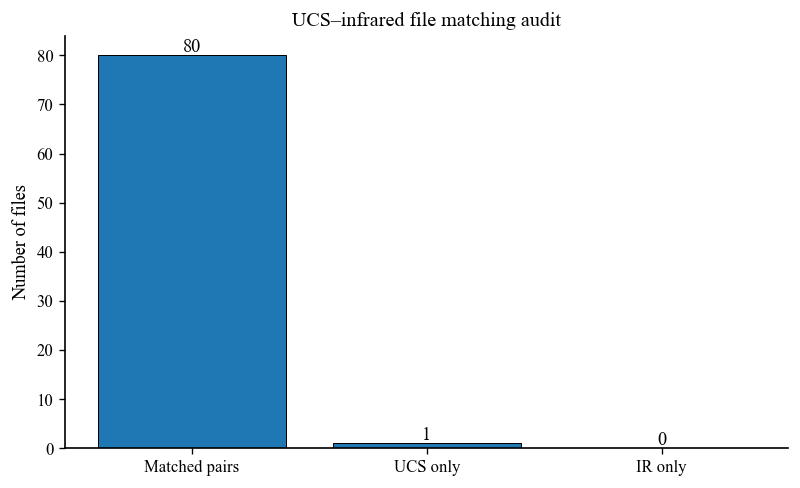

In [10]:
# ============================================================
# 10. Figure 1 — File matching audit
# ============================================================

matching_counts = pd.Series({
    "Matched pairs": int(matching_report["Matched"].sum()),
    "UCS only": int(
        (
            matching_report["UCS_File"].notna() &
            matching_report["IR_File"].isna()
        ).sum()
    ),
    "IR only": int(
        (
            matching_report["UCS_File"].isna() &
            matching_report["IR_File"].notna()
        ).sum()
    )
})

fig, ax = plt.subplots(figsize=(6.8, 4.2))
bars = ax.bar(
    matching_counts.index,
    matching_counts.values,
    edgecolor="black",
    linewidth=0.6
)

ax.set_ylabel("Number of files")
ax.set_title("UCS–infrared file matching audit")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

for bar, value in zip(bars, matching_counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(int(value)),
        ha="center",
        va="bottom"
    )

fig.savefig(
    FIGURE_DIR / "Figure_01_file_matching_audit.png",
    bbox_inches="tight"
)
fig.savefig(
    FIGURE_DIR / "Figure_01_file_matching_audit.tiff",
    bbox_inches="tight"
)
plt.show()


In [11]:
# ============================================================
# 11. Select representative specimens for signal plots
# ============================================================

sorted_qc = qc_summary.sort_values(
    "Synchronized_Duration_s"
).reset_index(drop=True)

representative_positions = np.unique(
    np.linspace(
        0,
        len(sorted_qc) - 1,
        min(4, len(sorted_qc)),
        dtype=int
    )
)

representative_ids = sorted_qc.loc[
    representative_positions,
    "Sample_ID"
].tolist()

print("Representative specimens:", representative_ids)


Representative specimens: ['G3-12', 'G3-4', 'G4-19', 'G1-1']


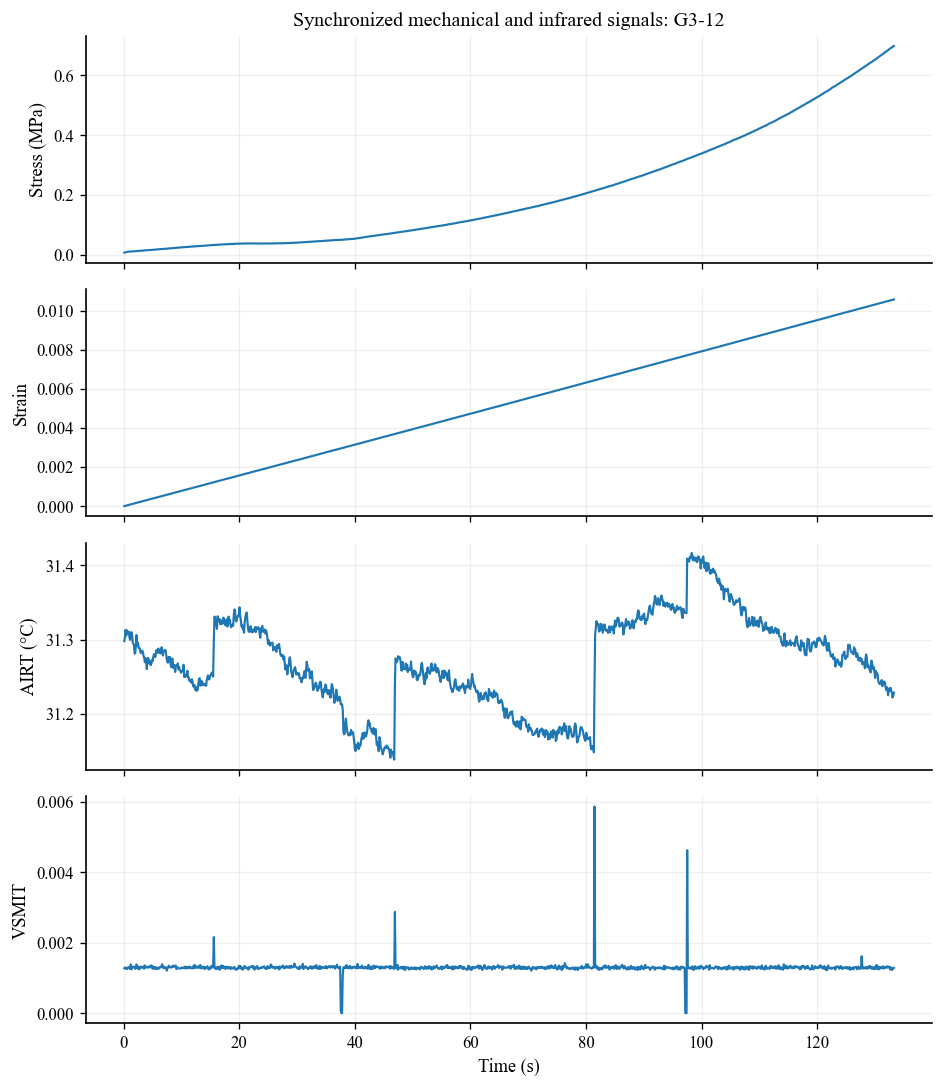

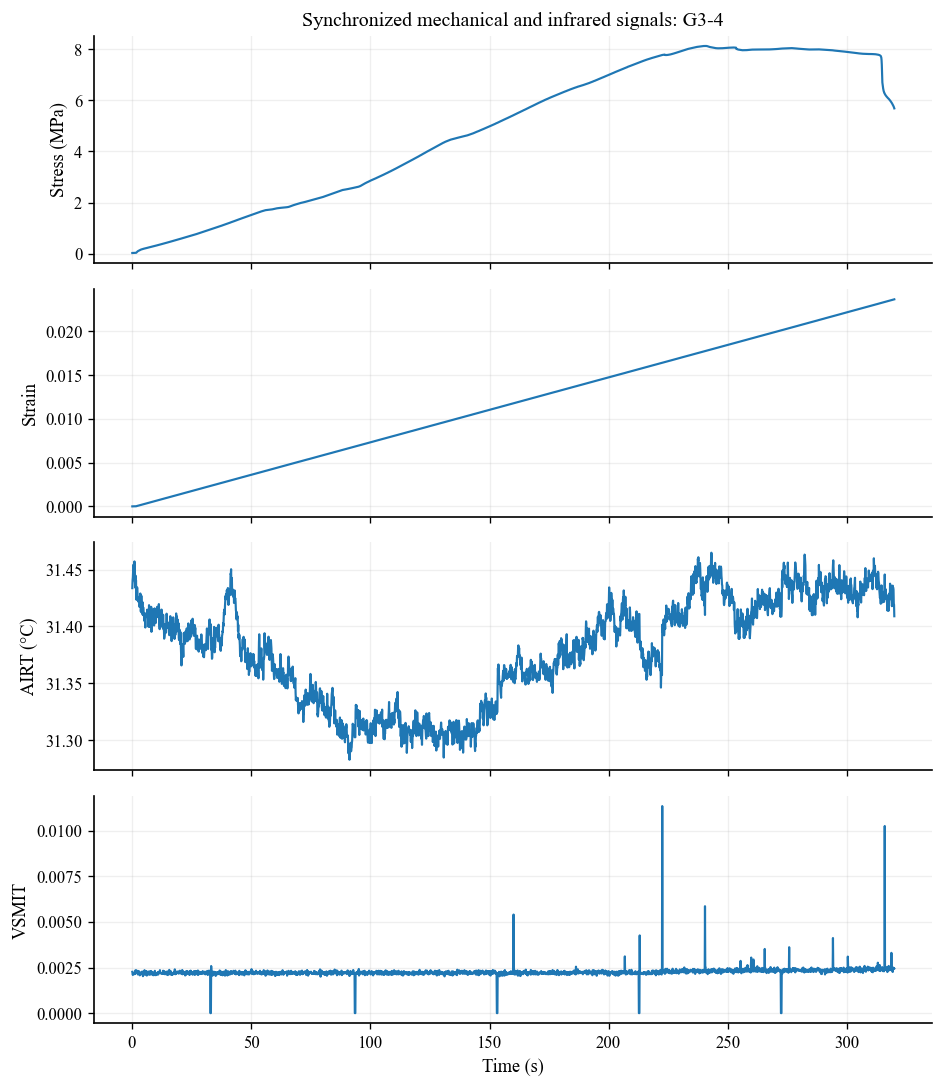

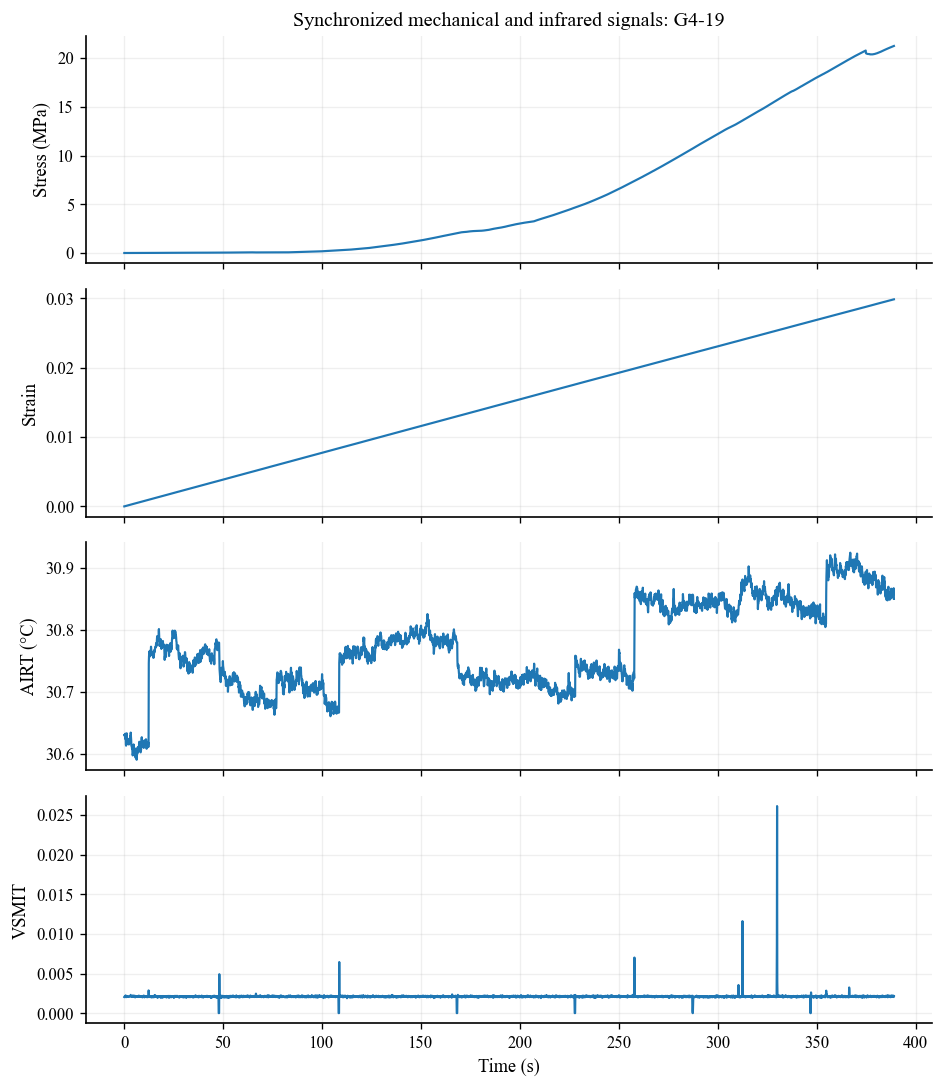

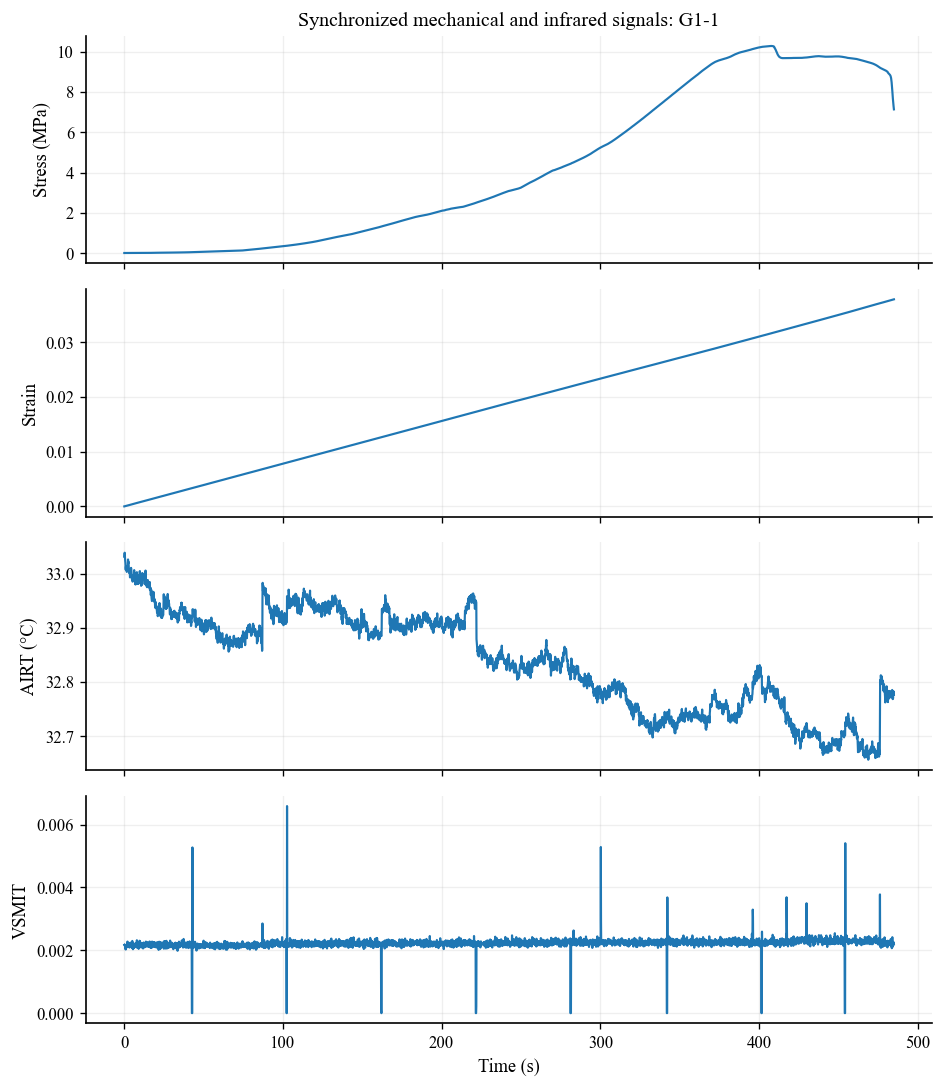

In [12]:
# ============================================================
# 12. Figure 2 — Four synchronized signals
# ============================================================

for sample_id in representative_ids:
    sample = master.loc[
        master["Sample_ID"] == sample_id
    ].sort_values("Time_s")

    fig, axes = plt.subplots(
        4,
        1,
        figsize=(8.0, 9.2),
        sharex=True
    )

    axes[0].plot(
        sample["Time_s"],
        sample["Stress_MPa"]
    )
    axes[0].set_ylabel("Stress (MPa)")
    axes[0].set_title(
        f"Synchronized mechanical and infrared signals: {sample_id}"
    )

    axes[1].plot(
        sample["Time_s"],
        sample["Strain"]
    )
    axes[1].set_ylabel("Strain")

    axes[2].plot(
        sample["Time_s"],
        sample["AIRT_C"]
    )
    axes[2].set_ylabel("AIRT (°C)")

    axes[3].plot(
        sample["Time_s"],
        sample["VSMIT"]
    )
    axes[3].set_ylabel("VSMIT")
    axes[3].set_xlabel("Time (s)")

    for axis in axes:
        axis.spines["top"].set_visible(False)
        axis.spines["right"].set_visible(False)
        axis.grid(alpha=0.2)

    fig.savefig(
        FIGURE_DIR /
        f"Figure_02_synchronized_signals_{sample_id}.png",
        bbox_inches="tight"
    )
    fig.savefig(
        FIGURE_DIR /
        f"Figure_02_synchronized_signals_{sample_id}.tiff",
        bbox_inches="tight"
    )
    plt.show()


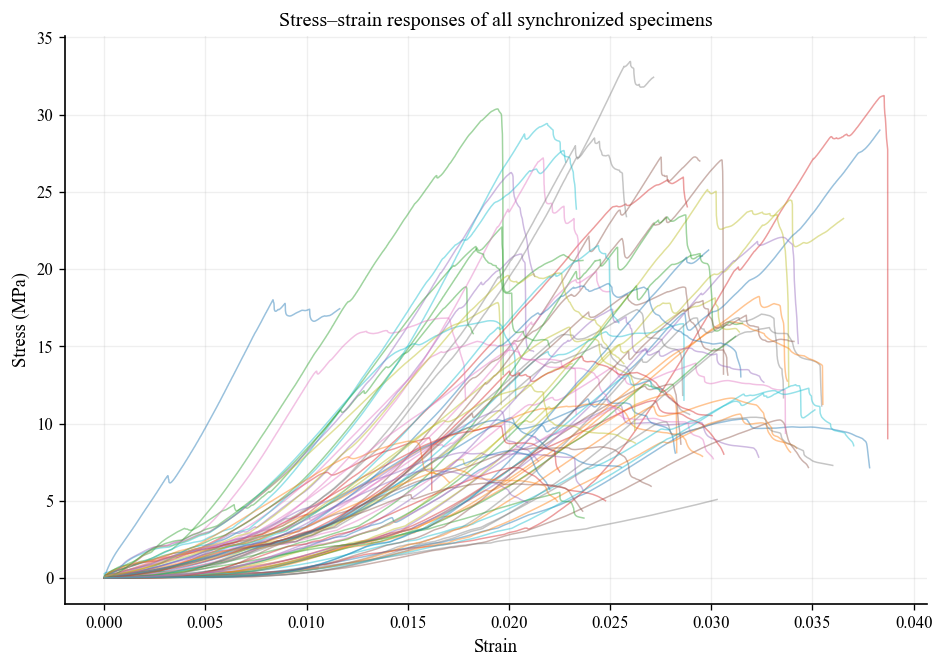

In [13]:
# ============================================================
# 13. Figure 3 — Stress–strain curves for all specimens
# ============================================================

fig, ax = plt.subplots(figsize=(8.0, 5.7))

for sample_id, sample in master.groupby("Sample_ID"):
    ax.plot(
        sample["Strain"],
        sample["Stress_MPa"],
        alpha=0.45,
        linewidth=0.9
    )

ax.set_xlabel("Strain")
ax.set_ylabel("Stress (MPa)")
ax.set_title("Stress–strain responses of all synchronized specimens")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(alpha=0.2)

fig.savefig(
    FIGURE_DIR / "Figure_03_all_stress_strain_curves.png",
    bbox_inches="tight"
)
fig.savefig(
    FIGURE_DIR / "Figure_03_all_stress_strain_curves.tiff",
    bbox_inches="tight"
)
plt.show()


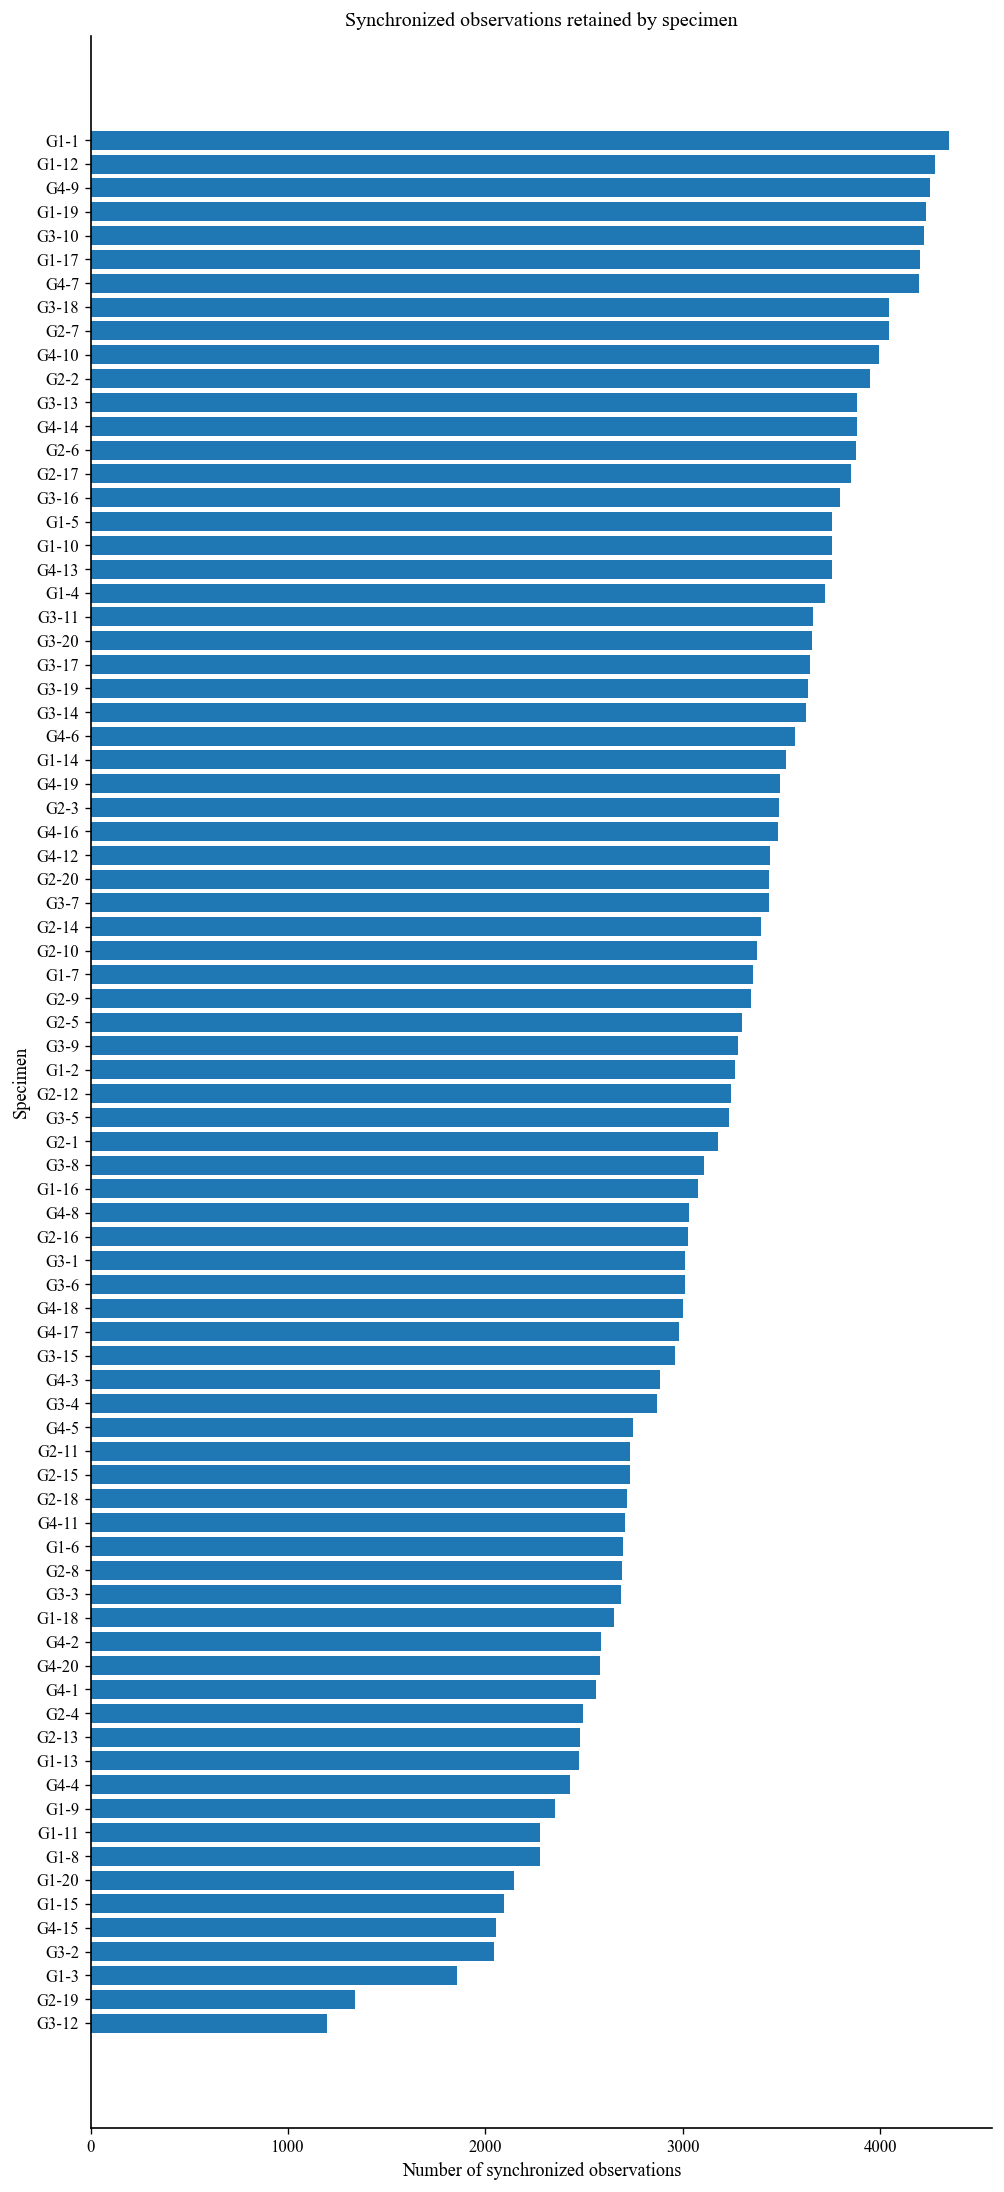

In [14]:
# ============================================================
# 14. Figure 4 — Synchronized rows per specimen
# ============================================================

rows_plot = qc_summary.sort_values(
    "Synchronized_Rows",
    ascending=True
)

figure_height = max(7, 0.23 * len(rows_plot))

fig, ax = plt.subplots(
    figsize=(8.5, figure_height)
)

ax.barh(
    rows_plot["Sample_ID"],
    rows_plot["Synchronized_Rows"]
)

ax.set_xlabel("Number of synchronized observations")
ax.set_ylabel("Specimen")
ax.set_title("Synchronized observations retained by specimen")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.savefig(
    FIGURE_DIR / "Figure_04_synchronized_rows_by_specimen.png",
    bbox_inches="tight"
)
fig.savefig(
    FIGURE_DIR / "Figure_04_synchronized_rows_by_specimen.tiff",
    bbox_inches="tight"
)
plt.show()


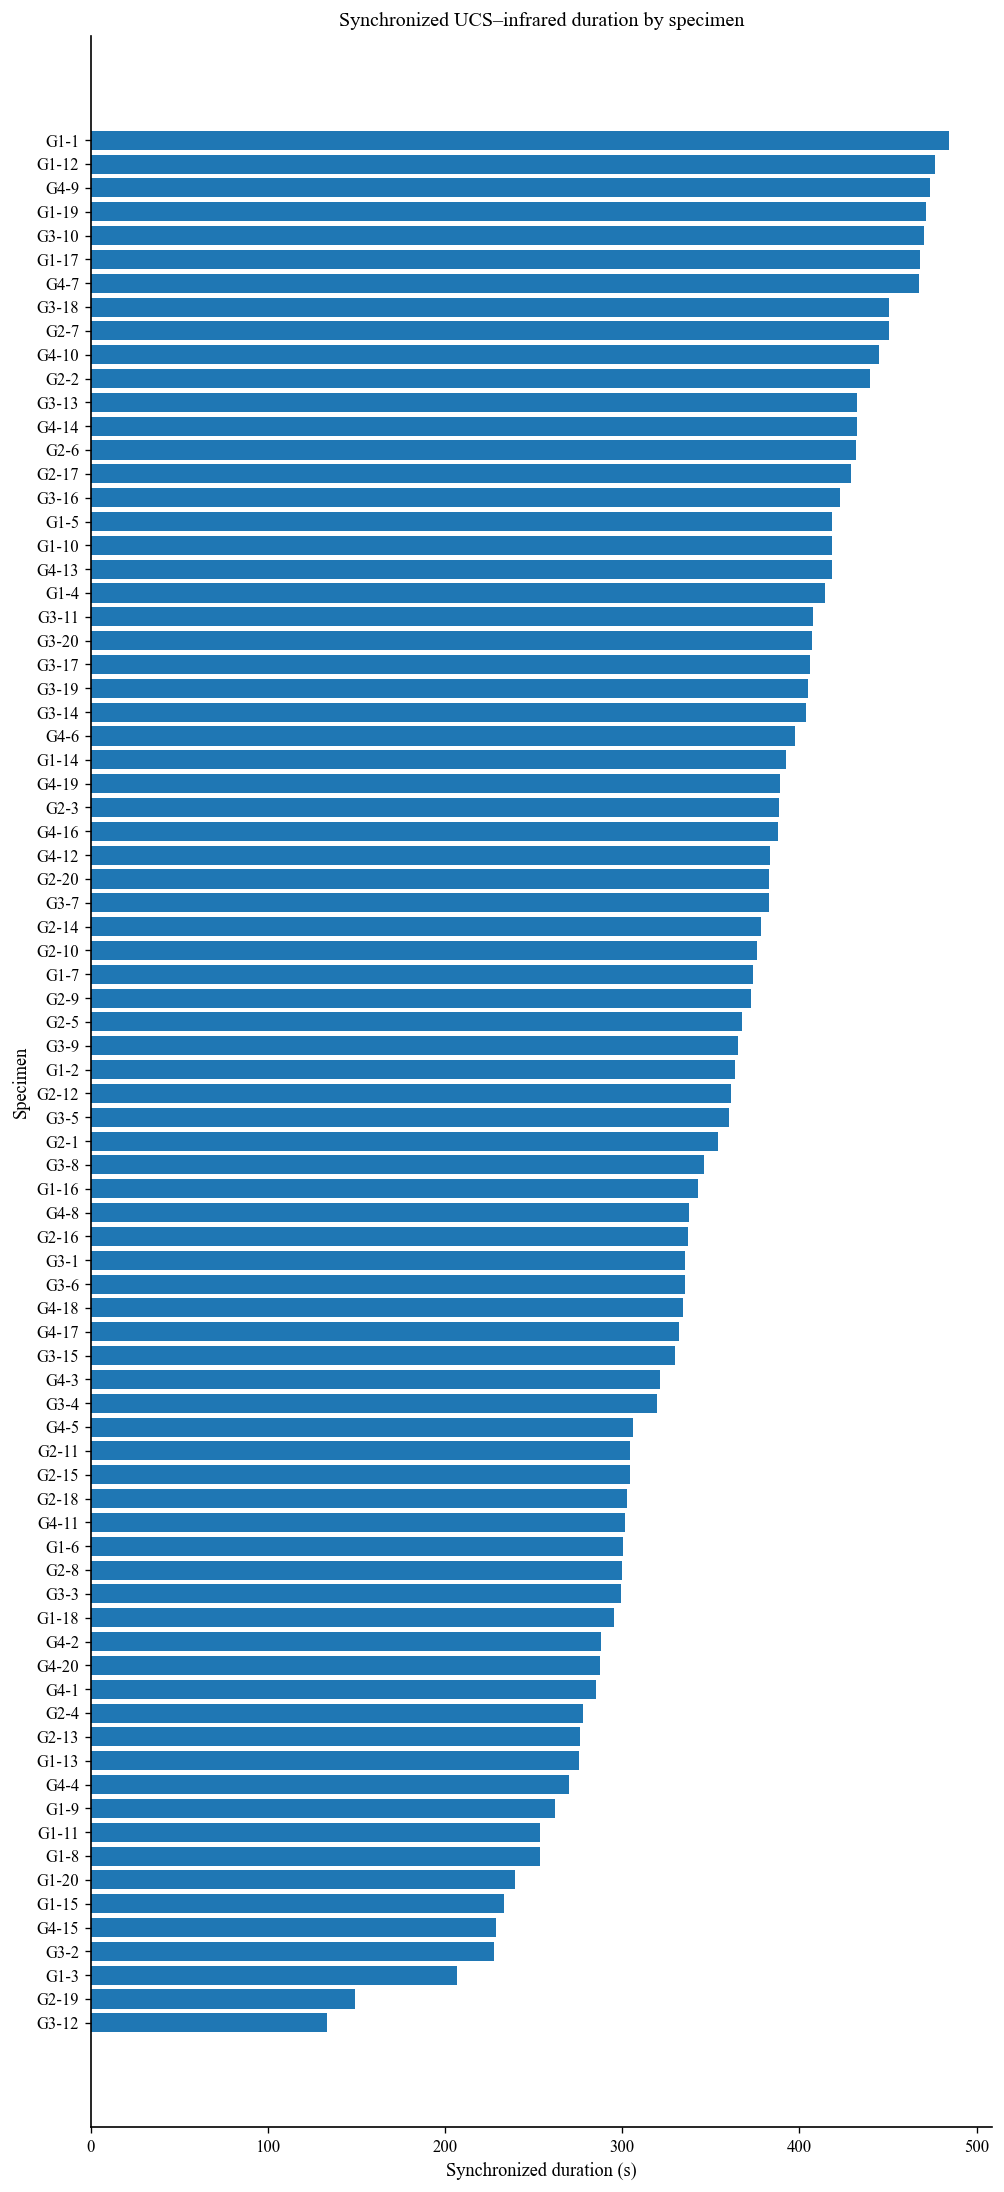

In [15]:
# ============================================================
# 15. Figure 5 — Test duration by specimen
# ============================================================

duration_plot = qc_summary.sort_values(
    "Synchronized_Duration_s",
    ascending=True
)

figure_height = max(7, 0.23 * len(duration_plot))

fig, ax = plt.subplots(
    figsize=(8.5, figure_height)
)

ax.barh(
    duration_plot["Sample_ID"],
    duration_plot["Synchronized_Duration_s"]
)

ax.set_xlabel("Synchronized duration (s)")
ax.set_ylabel("Specimen")
ax.set_title("Synchronized UCS–infrared duration by specimen")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.savefig(
    FIGURE_DIR / "Figure_05_test_duration_by_specimen.png",
    bbox_inches="tight"
)
fig.savefig(
    FIGURE_DIR / "Figure_05_test_duration_by_specimen.tiff",
    bbox_inches="tight"
)
plt.show()


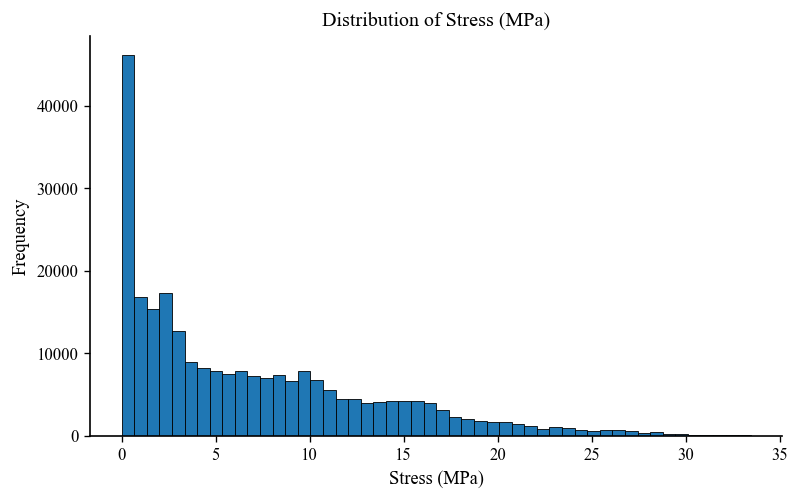

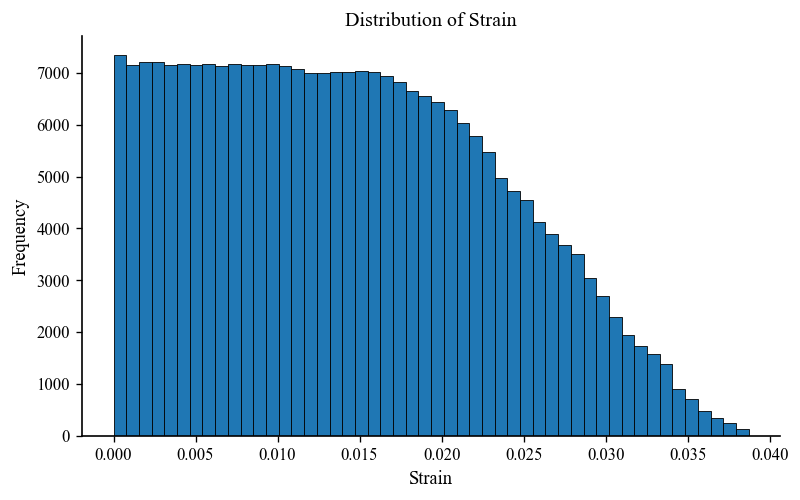

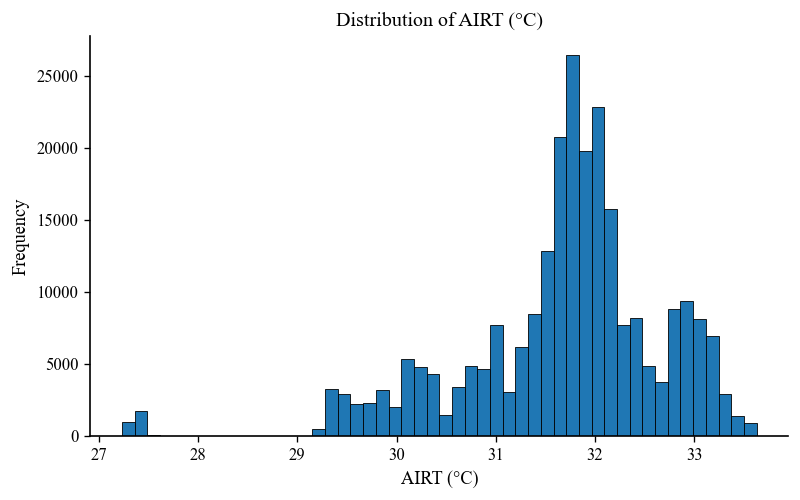

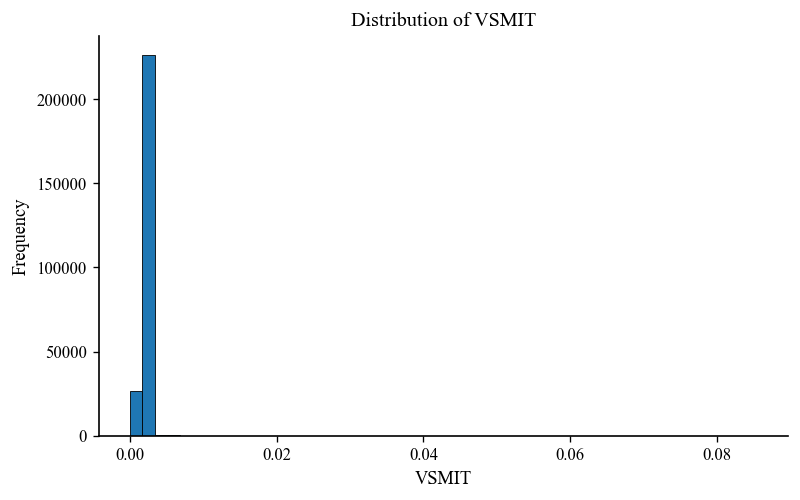

In [16]:
# ============================================================
# 16. Figure 6 — Predictor distributions
# ============================================================

labels = {
    "Stress_MPa": "Stress (MPa)",
    "Strain": "Strain",
    "AIRT_C": "AIRT (°C)",
    "VSMIT": "VSMIT"
}

for column, axis_label in labels.items():
    fig, ax = plt.subplots(figsize=(6.8, 4.3))

    ax.hist(
        master[column],
        bins=50,
        edgecolor="black",
        linewidth=0.5
    )

    ax.set_xlabel(axis_label)
    ax.set_ylabel("Frequency")
    ax.set_title(f"Distribution of {axis_label}")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    fig.savefig(
        FIGURE_DIR /
        f"Figure_06_distribution_{column}.png",
        bbox_inches="tight"
    )
    fig.savefig(
        FIGURE_DIR /
        f"Figure_06_distribution_{column}.tiff",
        bbox_inches="tight"
    )
    plt.show()


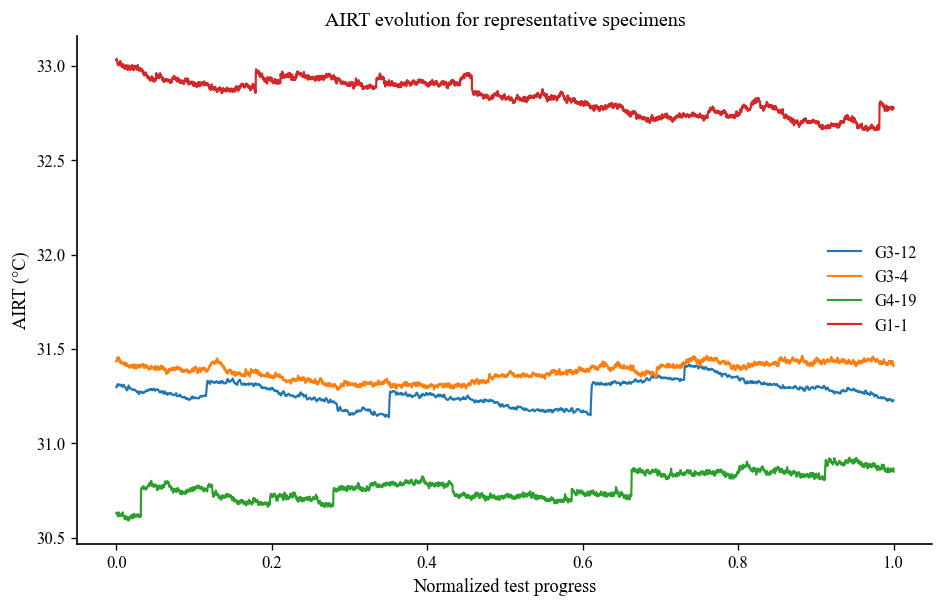

In [17]:
# ============================================================
# 17. Figure 7 — AIRT evolution against normalized progress
# ============================================================

fig, ax = plt.subplots(figsize=(8.0, 5.2))

for sample_id in representative_ids:
    sample = master.loc[
        master["Sample_ID"] == sample_id
    ].sort_values("Test_Progress")

    ax.plot(
        sample["Test_Progress"],
        sample["AIRT_C"],
        label=sample_id
    )

ax.set_xlabel("Normalized test progress")
ax.set_ylabel("AIRT (°C)")
ax.set_title("AIRT evolution for representative specimens")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False)

fig.savefig(
    FIGURE_DIR / "Figure_07_AIRT_normalized_progress.png",
    bbox_inches="tight"
)
fig.savefig(
    FIGURE_DIR / "Figure_07_AIRT_normalized_progress.tiff",
    bbox_inches="tight"
)
plt.show()


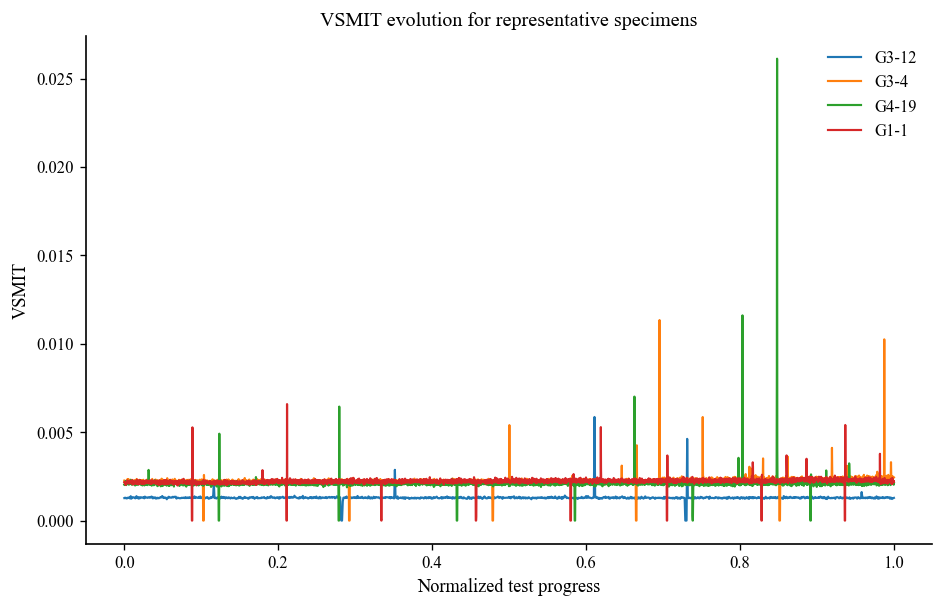

In [18]:
# ============================================================
# 18. Figure 8 — VSMIT evolution against normalized progress
# ============================================================

fig, ax = plt.subplots(figsize=(8.0, 5.2))

for sample_id in representative_ids:
    sample = master.loc[
        master["Sample_ID"] == sample_id
    ].sort_values("Test_Progress")

    ax.plot(
        sample["Test_Progress"],
        sample["VSMIT"],
        label=sample_id
    )

ax.set_xlabel("Normalized test progress")
ax.set_ylabel("VSMIT")
ax.set_title("VSMIT evolution for representative specimens")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False)

fig.savefig(
    FIGURE_DIR / "Figure_08_VSMIT_normalized_progress.png",
    bbox_inches="tight"
)
fig.savefig(
    FIGURE_DIR / "Figure_08_VSMIT_normalized_progress.tiff",
    bbox_inches="tight"
)
plt.show()


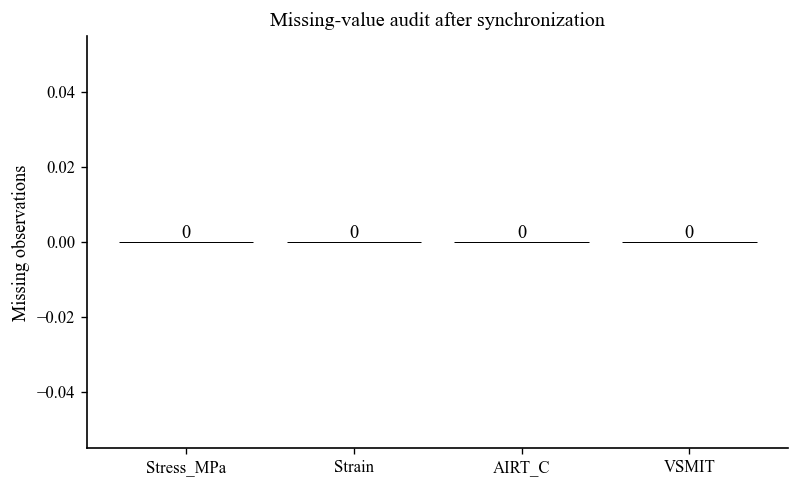

In [19]:
# ============================================================
# 19. Figure 9 — Missing-value audit
# ============================================================

missing_counts = master[
    ["Stress_MPa", "Strain", "AIRT_C", "VSMIT"]
].isna().sum()

fig, ax = plt.subplots(figsize=(6.8, 4.2))

bars = ax.bar(
    missing_counts.index,
    missing_counts.values,
    edgecolor="black",
    linewidth=0.6
)

ax.set_ylabel("Missing observations")
ax.set_title("Missing-value audit after synchronization")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

for bar, value in zip(bars, missing_counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(int(value)),
        ha="center",
        va="bottom"
    )

fig.savefig(
    FIGURE_DIR / "Figure_09_missing_value_audit.png",
    bbox_inches="tight"
)
fig.savefig(
    FIGURE_DIR / "Figure_09_missing_value_audit.tiff",
    bbox_inches="tight"
)
plt.show()


In [20]:
# ============================================================
# 20. Export the synchronized master dataset
# ============================================================

preferred_columns = [
    "Sample_ID",
    "Observation_ID",
    "Time_s",
    "Test_Progress",
    "Stress_MPa",
    "Strain",
    "AIRT_C",
    "VSMIT",
    "UCS_File",
    "IR_File",
    "Synchronization_Method"
]

other_columns = [
    column for column in master.columns
    if column not in preferred_columns
]

master = master[
    [column for column in preferred_columns if column in master.columns] +
    other_columns
]

master_csv = (
    OUTPUT_DIR /
    "CNT_backfill_master_synchronized.csv"
)

master_excel = (
    OUTPUT_DIR /
    "CNT_backfill_master_synchronized.xlsx"
)

master_parquet = (
    OUTPUT_DIR /
    "CNT_backfill_master_synchronized.parquet"
)

master.to_csv(
    master_csv,
    index=False
)

with pd.ExcelWriter(
    master_excel,
    engine="openpyxl"
) as writer:
    master.to_excel(
        writer,
        sheet_name="Master_Data",
        index=False
    )
    qc_summary.to_excel(
        writer,
        sheet_name="QC_Summary",
        index=False
    )
    matching_report.to_excel(
        writer,
        sheet_name="File_Matching",
        index=False
    )
    validation_summary.to_excel(
        writer,
        sheet_name="Validation",
        index=False
    )

    if not processing_errors.empty:
        processing_errors.to_excel(
            writer,
            sheet_name="Processing_Errors",
            index=False
        )

try:
    master.to_parquet(
        master_parquet,
        index=False
    )
    parquet_status = "Saved"
except Exception as error:
    parquet_status = f"Not saved: {error}"

qc_summary.to_csv(
    QC_DIR / "02_processing_qc_summary.csv",
    index=False
)
validation_summary.to_csv(
    QC_DIR / "03_validation_summary.csv",
    index=False
)

if not processing_errors.empty:
    processing_errors.to_csv(
        QC_DIR / "04_processing_errors.csv",
        index=False
    )

print("Master CSV:", master_csv)
print("Master Excel:", master_excel)
print("Parquet:", parquet_status)
print("Figures:", FIGURE_DIR)


Master CSV: C:\Users\Eddie\Desktop\new_exp_june\Project_Dir\master_dataset_outputs\CNT_backfill_master_synchronized.csv
Master Excel: C:\Users\Eddie\Desktop\new_exp_june\Project_Dir\master_dataset_outputs\CNT_backfill_master_synchronized.xlsx
Parquet: Saved
Figures: C:\Users\Eddie\Desktop\new_exp_june\Project_Dir\master_dataset_outputs\figures


In [21]:
# ============================================================
# 21. Final summary
# ============================================================

final_summary = {
    "matched_specimen_pairs": int(
        matching_report["Matched"].sum()
    ),
    "successfully_processed_specimens": int(
        master["Sample_ID"].nunique()
    ),
    "failed_specimens": int(
        len(processing_errors)
    ),
    "master_observations": int(
        len(master)
    ),
    "master_columns": int(
        master.shape[1]
    ),
    "model_predictors": [
        "Stress_MPa",
        "Strain",
        "AIRT_C",
        "VSMIT"
    ],
    "output_directory": str(
        OUTPUT_DIR
    )
}

print(json.dumps(final_summary, indent=2))

display(master.head(10))
display(master.tail(10))


{
  "matched_specimen_pairs": 80,
  "successfully_processed_specimens": 80,
  "failed_specimens": 0,
  "master_observations": 253701,
  "master_columns": 11,
  "model_predictors": [
    "Stress_MPa",
    "Strain",
    "AIRT_C",
    "VSMIT"
  ],
  "output_directory": "C:\\Users\\Eddie\\Desktop\\new_exp_june\\Project_Dir\\master_dataset_outputs"
}


,Sample_ID,Observation_ID,Time_s,Test_Progress,Stress_MPa,Strain,AIRT_C,VSMIT,UCS_File,IR_File,Synchronization_Method
0,G1-1,1,0.109,0.000000,0.008862,0.000003,33.031681,0.002169,G1-1_processed.xlsx,G1-1_AIRT_VSMIT.csv,IR interpolated onto UCS time grid
1,G1-1,2,0.218,0.000225,0.009167,0.000012,33.036082,0.002161,G1-1_processed.xlsx,G1-1_AIRT_VSMIT.csv,IR interpolated onto UCS time grid
2,G1-1,3,0.343,0.000483,0.009778,0.000021,33.039031,0.002182,G1-1_processed.xlsx,G1-1_AIRT_VSMIT.csv,IR interpolated onto UCS time grid
3,G1-1,4,0.452,0.000708,0.010084,0.000030,33.032625,0.002172,G1-1_processed.xlsx,G1-1_AIRT_VSMIT.csv,IR interpolated onto UCS time grid
4,G1-1,5,0.561,0.000932,0.009778,0.000039,33.027376,0.002120,G1-1_processed.xlsx,G1-1_AIRT_VSMIT.csv,IR interpolated onto UCS time grid
5,G1-1,6,0.671,0.001159,0.010084,0.000049,33.023620,0.002145,G1-1_processed.xlsx,G1-1_AIRT_VSMIT.csv,IR interpolated onto UCS time grid
6,G1-1,7,0.780,0.001384,0.009778,0.000055,33.020499,0.002148,G1-1_processed.xlsx,G1-1_AIRT_VSMIT.csv,IR interpolated onto UCS time grid
7,G1-1,8,0.889,0.001609,0.009778,0.000064,33.013705,0.002033,G1-1_processed.xlsx,G1-1_AIRT_VSMIT.csv,IR interpolated onto UCS time grid
8,G1-1,9,0.998,0.001834,0.009778,0.000073,33.007526,0.002120,G1-1_processed.xlsx,G1-1_AIRT_VSMIT.csv,IR interpolated onto UCS time grid
9,G1-1,10,1.123,0.002092,0.010390,0.000082,33.013344,0.002030,G1-1_processed.xlsx,G1-1_AIRT_VSMIT.csv,IR interpolated onto UCS time grid


,Sample_ID,Observation_ID,Time_s,Test_Progress,Stress_MPa,Strain,AIRT_C,VSMIT,UCS_File,IR_File,Synchronization_Method
253691,G4-9,4243,472.696,0.997893,8.819272,0.036957,31.793825,0.001775,G4-9_processed.xlsx,G4-9_AIRT_VSMIT.csv,IR interpolated onto UCS time grid
253692,G4-9,4244,472.805,0.998123,8.796659,0.036966,31.791731,0.001964,G4-9_processed.xlsx,G4-9_AIRT_VSMIT.csv,IR interpolated onto UCS time grid
253693,G4-9,4245,472.914,0.998353,8.783825,0.036975,31.790190,0.001886,G4-9_processed.xlsx,G4-9_AIRT_VSMIT.csv,IR interpolated onto UCS time grid
253694,G4-9,4246,473.024,0.998585,8.763657,0.036984,31.792692,0.001874,G4-9_processed.xlsx,G4-9_AIRT_VSMIT.csv,IR interpolated onto UCS time grid
253695,G4-9,4247,473.148,0.998847,8.737988,0.036993,31.775903,0.001900,G4-9_processed.xlsx,G4-9_AIRT_VSMIT.csv,IR interpolated onto UCS time grid
253696,G4-9,4248,473.258,0.999079,8.708958,0.037003,31.780147,0.001873,G4-9_processed.xlsx,G4-9_AIRT_VSMIT.csv,IR interpolated onto UCS time grid
253697,G4-9,4249,473.367,0.999309,8.671678,0.037012,31.779782,0.001918,G4-9_processed.xlsx,G4-9_AIRT_VSMIT.csv,IR interpolated onto UCS time grid
253698,G4-9,4250,473.476,0.999540,8.643870,0.037021,31.787394,0.001795,G4-9_processed.xlsx,G4-9_AIRT_VSMIT.csv,IR interpolated onto UCS time grid
253699,G4-9,4251,473.585,0.999770,8.618202,0.037030,31.786255,0.001803,G4-9_processed.xlsx,G4-9_AIRT_VSMIT.csv,IR interpolated onto UCS time grid
253700,G4-9,4252,473.694,1.000000,8.562281,0.037036,31.781042,0.001898,G4-9_processed.xlsx,G4-9_AIRT_VSMIT.csv,IR interpolated onto UCS time grid


## Main output for the next notebook

```text
master_dataset_outputs/CNT_backfill_master_synchronized.xlsx
```

The next notebook will use this synchronized dataset to:

1. identify the peak point for each specimen;
2. create defensible failure-stage labels;
3. visualize the labelled stages;
4. prepare grouped, leakage-safe training data.
